# CDC Diabetes Health Indicators: final benchmark

ESILV A4 DIA3 — Louis Le Forestier and Team

**Question.** How much do self-reported health indicators improve classification of current survey diabetes status beyond lifestyle and demographic information?

This notebook reports an executed, reproducible experiment on the full UCI binary export. It distinguishes development selection from the reserved test evaluation. All tables and figures below come from saved experiment outputs, not assumed scores.

**Execution:** run cells from top to bottom. The default checks the saved source fingerprints and displays results. Set `RERUN_EXPERIMENTS=1` to rerun all fitting before displaying the report; missing results also trigger a full run. See the README for installation and noninteractive execution.

## 1. Environment and source verification

In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run from the repository or notebooks directory."
sys.path.insert(0, str(ROOT))
from src.experiment import run

OUT = ROOT / "results"
if os.environ.get("RERUN_EXPERIMENTS") == "1" or not (OUT / "run_manifest.json").exists():
    run()
manifest = json.loads((OUT / "run_manifest.json").read_text())
for name, expected in manifest["source_sha256"].items():
    actual = hashlib.sha256((ROOT / "src" / name).read_bytes()).hexdigest()
    assert actual == expected, f"Source changed: {name}. Rerun with RERUN_EXPERIMENTS=1."
print("Completed run:", manifest["completed_at_utc"])
print("Python:", manifest["python"], "Libraries:", manifest["versions"])
print("Experiment duration (seconds):", round(manifest["elapsed_seconds"], 2))
pd.set_option("display.max_colwidth", 110)


Completed run: 2026-11-16T12:19:23.460770+00:00
Python: 3.14.10 Libraries: {'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.1'}
Experiment duration (seconds): 70.06


## 2. Data provenance and integrity

Source: [UCI dataset 891](https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators), [exact binary CSV](https://archive.ics.uci.edu/static/public/891/data.csv), DOI [10.24432/C53919](https://doi.org/10.24432/C53919).

The selected variable dictionary codes `Diabetes_binary=1` as prediabetes or diabetes and `0` as no diabetes. The landing page also describes a three-class variant, so the exact binary file and checksum define this study. It is not a future-onset label. `ID` never enters a model, and `Age` represents a band.

Acquisition rejects checksum changes, unexpected columns, target counts, missing values and out-of-range categories. The raw CSV remains outside version control. Matching response profiles are retained because they do not establish that two rows belong to the same person.

In [2]:
audit = json.loads((OUT / "data_audit.json").read_text())
display(pd.Series(audit).to_frame("value"))

,value
source,"{'url': 'https://archive.ics.uci.edu/static/public/891/data.csv', 'sha256': '9f71fda9d4ae5f4878c99b9233b6a..."
rows,253680
columns,"[ID, Diabetes_binary, HighBP, HighChol, CholCheck, BMI, Smoker, Stroke, HeartDiseaseorAttack, PhysActivity..."
missing_values,0
target_counts,"{'0': 218334, '1': 35346}"
development_rows,202944
test_rows,50736
repeated_development_predictor_profiles,18580
duplicate_policy,Retained: identical responses do not identify repeated participants
development_index_sha256,88d26edb9eebc3f1f4c69a0ccc11ee832f1926853fcdf9a1b4835bbd00a829f0


## 3. Development-only exploratory analysis

A fixed stratified 80/20 split (seed 42) reserves 50,736 observations for final evaluation. The following distributions, summaries and associations use only the 202,944 development observations. Acquisition checks the full schema and known target counts solely to identify the exact export.

There are no missing values, so no imputer is needed. All integer-coded predictors are retained in their original form; ordinal bands are treated as ordered numerical values. This assumes equal log-odds increments in the logistic model. Scaling is fitted within folds. Tree models can learn nonlinear splits without scaling.

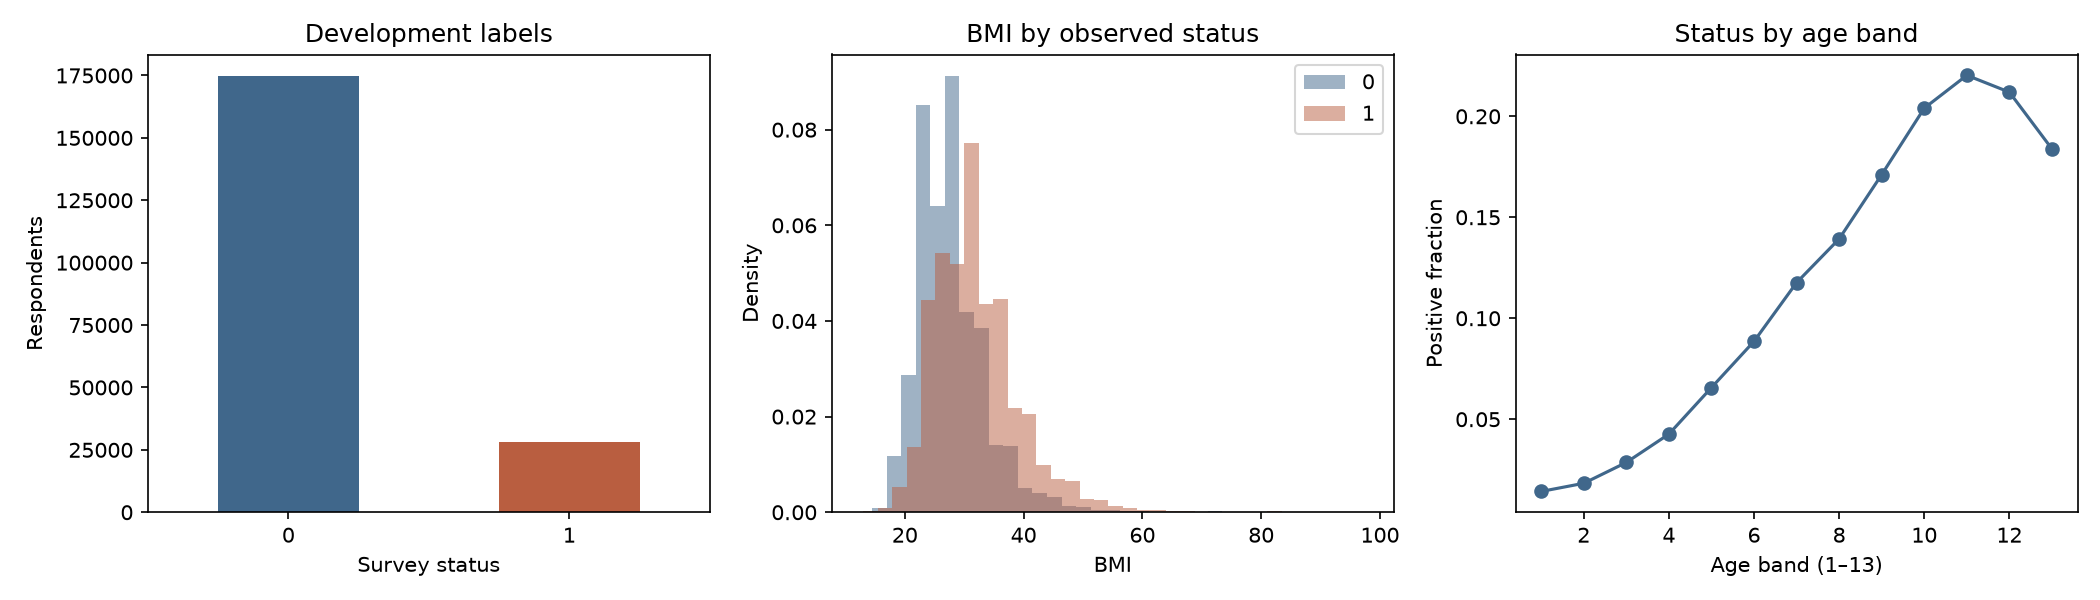

,count,mean,std,min,25%,50%,75%,max
PhysActivity,202944.0,0.757,0.429,0.0,1.0,1.0,1.0,1.0
Fruits,202944.0,0.634,0.482,0.0,0.0,1.0,1.0,1.0
Veggies,202944.0,0.811,0.391,0.0,1.0,1.0,1.0,1.0
Smoker,202944.0,0.443,0.497,0.0,0.0,0.0,1.0,1.0
HvyAlcoholConsump,202944.0,0.056,0.229,0.0,0.0,0.0,0.0,1.0
Sex,202944.0,0.441,0.497,0.0,0.0,0.0,1.0,1.0
Age,202944.0,8.033,3.051,1.0,6.0,8.0,10.0,13.0
Education,202944.0,5.050,0.986,1.0,4.0,5.0,6.0,6.0
Income,202944.0,6.051,2.073,1.0,5.0,7.0,8.0,8.0
BMI,202944.0,28.378,6.598,12.0,24.0,27.0,31.0,98.0


In [3]:
display(Image(filename=str(OUT / "eda.png")))
display(pd.read_csv(OUT / "development_describe.csv", index_col=0).round(3))

## 4. Predeclared models and feature sets

- Lifestyle and demographics: physical activity, fruit and vegetable consumption, smoking, heavy alcohol consumption, sex, age band, education and income (9 predictors).
- Enriched: those 9 plus 10 health indicators and 2 healthcare-access variables (21 predictors).
- Each set: majority-class baseline; logistic regression (`C=0.1, 1, 10`); balanced logistic regression; depth-3/5 trees; Gaussian naive Bayes; random forest (100 trees, depth 12, minimum leaf size 10); histogram gradient boosting (150 iterations, learning rate 0.08, 15/31 leaves).
- Enriched logistic feature selection: mutual information and RFE with 5/10 variables; L1 selectors with `C=0.001/0.01`, followed by logistic regression with `C=1`.

The total budget is **28 configurations × 5 folds**. Each uses exactly the same shuffled stratified development folds. Every scaler and feature selector is fitted inside its training fold. Mutual information treats the integer-coded survey variables as discrete. RFE removes up to four features per iteration. Class balancing is a candidate, not applied globally.

The primary metric is **average precision (AP)**, not trapezoidal PR-AUC. Mean fold AP selects the model; fold SD describes variation, not a confidence interval. These selection scores are not an unbiased nested-CV estimate.

,candidate,group,model,cv_ap_mean,cv_ap_sd,feature_count_mean,cv_fit_seconds
20,enriched/gradient_boosting_leaf15,enriched,gradient_boosting_leaf15,0.4359,0.0084,21.0,6.9895
21,enriched/gradient_boosting_leaf31,enriched,gradient_boosting_leaf31,0.4354,0.0078,21.0,7.7916
19,enriched/random_forest,enriched,random_forest,0.4311,0.0067,21.0,10.1645
12,enriched/logistic_C0.1,enriched,logistic_C0.1,0.4076,0.0049,21.0,0.1729
13,enriched/logistic_C1,enriched,logistic_C1,0.4076,0.0049,21.0,0.1670
14,enriched/logistic_C10,enriched,logistic_C10,0.4076,0.0049,21.0,0.1692
27,enriched/l1_C0.01,enriched,l1_C0.01,0.4076,0.0049,19.4,0.9820
26,enriched/l1_C0.001,enriched,l1_C0.001,0.4066,0.0049,13.0,0.7699
15,enriched/logistic_balanced,enriched,logistic_balanced,0.4060,0.0046,21.0,0.2216
25,enriched/rfe_k10,enriched,rfe_k10,0.4048,0.0055,10.0,0.6460


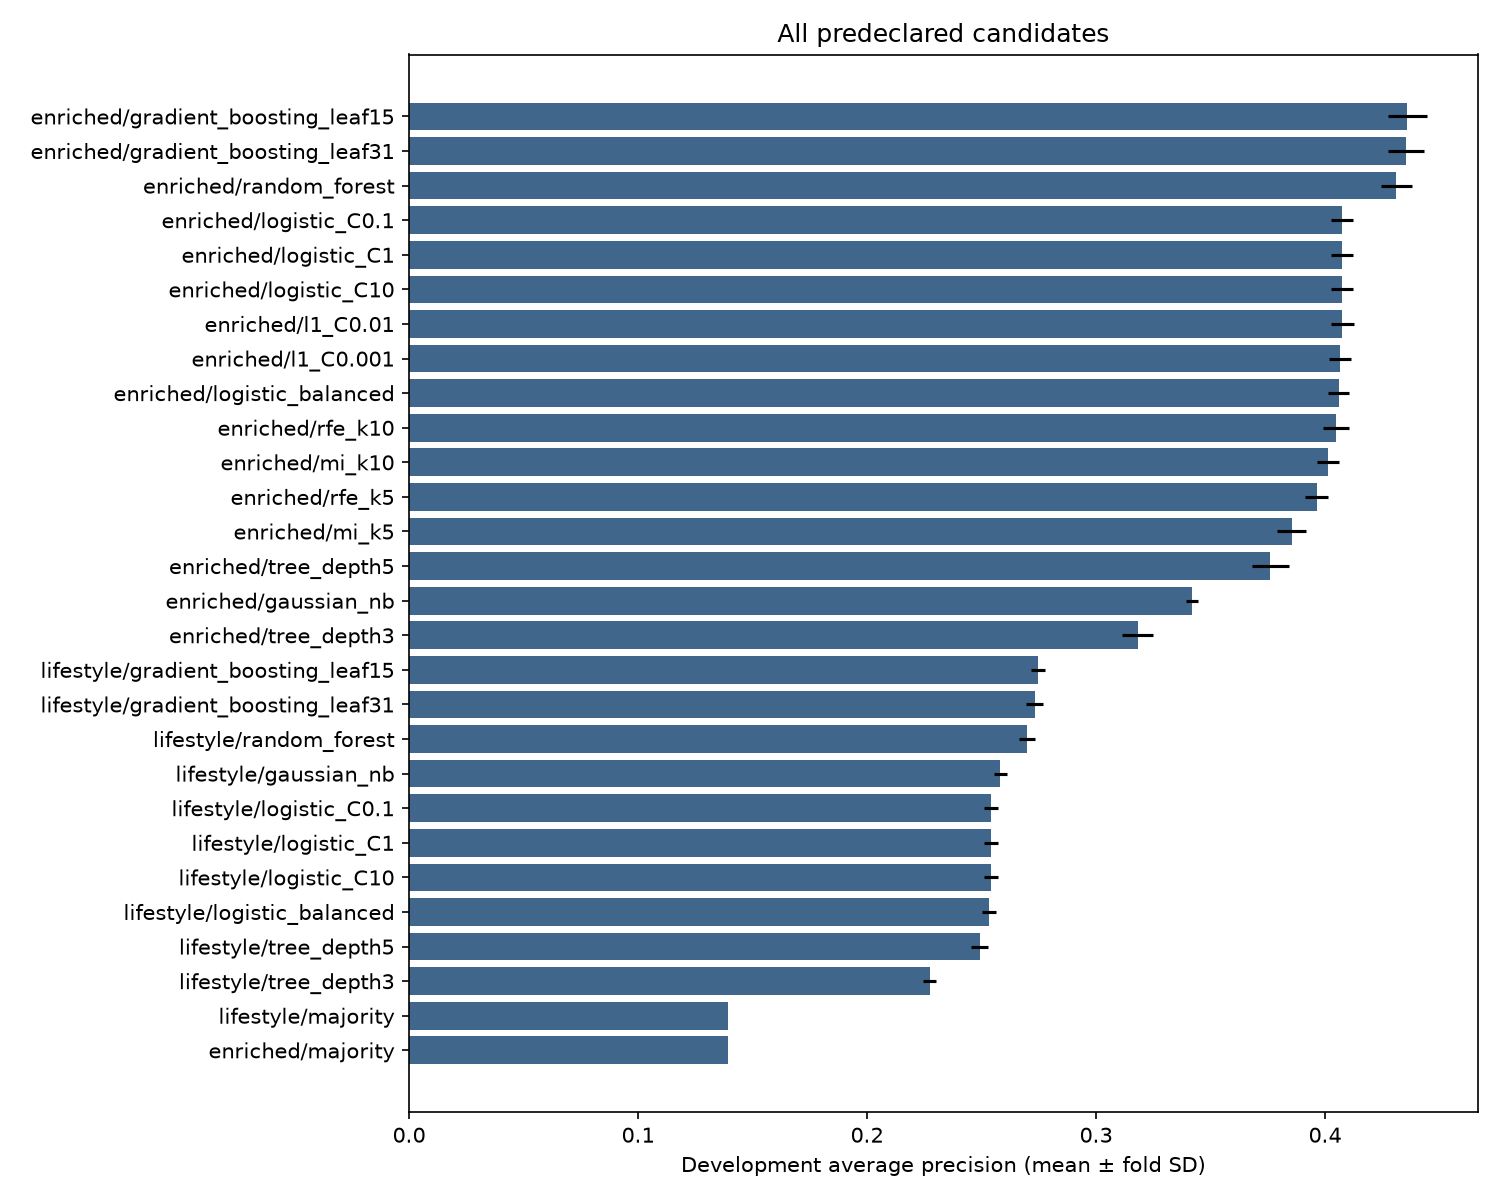

In [4]:
cv = pd.read_csv(OUT / "cv_summary.csv").sort_values("cv_ap_mean", ascending=False)
display(cv.round(4))
display(Image(filename=str(OUT / "cv_comparison.png")))

## 5. Threshold selection and configuration freeze

The highest development-AP candidate becomes the primary model. The best model from each feature set, the two `C=1` logistic baselines, the majority baseline and the best candidate from each selection method are frozen for comparison.

Each nontrivial finalist uses the threshold maximizing F1 on its **out-of-fold development probabilities**. F1 is a reproducible experimental operating criterion, not a clinical cost function. A threshold of 0.5 is also reported. `frozen_protocol.json` is written before test evaluation. The same development data select models and thresholds, so the test is the final performance check.

In [5]:
frozen = json.loads((OUT / "frozen_protocol.json").read_text())
print("Frozen at:", frozen["frozen_at_utc"])
print("Primary model:", frozen["primary_candidate"])
thresholds = pd.read_csv(OUT / "development_thresholds.csv")
display(thresholds[thresholds.candidate == frozen["primary_candidate"]][
    ["threshold", "precision", "recall", "f1", "false_positive_rate"]].round(4))

Frozen at: 2026-11-16T12:19:15.085937+00:00
Primary model: enriched/gradient_boosting_leaf15


,threshold,precision,recall,f1,false_positive_rate
0,0.1000,0.2746,0.8654,0.4169,0.3702
1,0.1500,0.3178,0.7700,0.4499,0.2676
2,0.2000,0.3583,0.6762,0.4684,0.1961
3,0.2316,0.3827,0.6183,0.4728,0.1615
4,0.2500,0.3958,0.5816,0.4711,0.1437
5,0.3000,0.4322,0.4858,0.4575,0.1033
6,0.4000,0.5069,0.3134,0.3873,0.0494
7,0.5000,0.5834,0.1657,0.2581,0.0192


## 6. Final held-out evaluation

All finalists are refitted on the entire development split. Their configurations and thresholds stay fixed. The table contains both the conventional 0.5 operating point and the development-selected operating point. `tn/fp/fn/tp` use rows = actual class and columns = predicted class in the usual binary confusion matrix.

The majority baseline makes the imbalance explicit: high accuracy can coexist with zero recall. Test results are descriptive comparisons; they are not used to replace the development-selected winner.

,candidate,operating_point,average_precision,roc_auc,brier,accuracy,balanced_accuracy,precision,recall,f1,false_positive_rate,tn,fp,fn,tp,threshold,n
1,enriched/gradient_boosting_leaf15,development_f1,0.4247,0.8274,0.0973,0.8069,0.7249,0.3801,0.6111,0.4687,0.1614,36621,7046,2749,4320,0.2316,50736
3,enriched/l1_C0.01,development_f1,0.3942,0.8192,0.1000,0.7975,0.7195,0.3648,0.6114,0.4569,0.1724,36140,7527,2747,4322,0.2095,50736
5,enriched/logistic_C1,development_f1,0.3942,0.8192,0.1000,0.7996,0.7179,0.3669,0.6046,0.4567,0.1689,36293,7374,2795,4274,0.2126,50736
7,enriched/majority,development_f1,0.1393,0.5000,0.1393,0.8607,0.5000,0.0000,0.0000,0.0000,0.0000,43667,0,7069,0,0.5000,50736
9,enriched/mi_k10,development_f1,0.3886,0.8149,0.1006,0.7963,0.7148,0.3613,0.6019,0.4516,0.1723,36145,7522,2814,4255,0.2093,50736
11,enriched/rfe_k10,development_f1,0.3928,0.8186,0.1000,0.7994,0.7168,0.3663,0.6023,0.4556,0.1687,36301,7366,2811,4258,0.2125,50736
13,lifestyle/gradient_boosting_leaf15,development_f1,0.2763,0.7244,0.1108,0.7045,0.6527,0.2545,0.5808,0.3539,0.2755,31637,12030,2963,4106,0.1799,50736
15,lifestyle/logistic_C1,development_f1,0.2571,0.7113,0.1126,0.6707,0.6500,0.2384,0.6213,0.3446,0.3213,29638,14029,2677,4392,0.1483,50736


,Predicted 0,Predicted 1
Actual 0,36621,7046
Actual 1,2749,4320


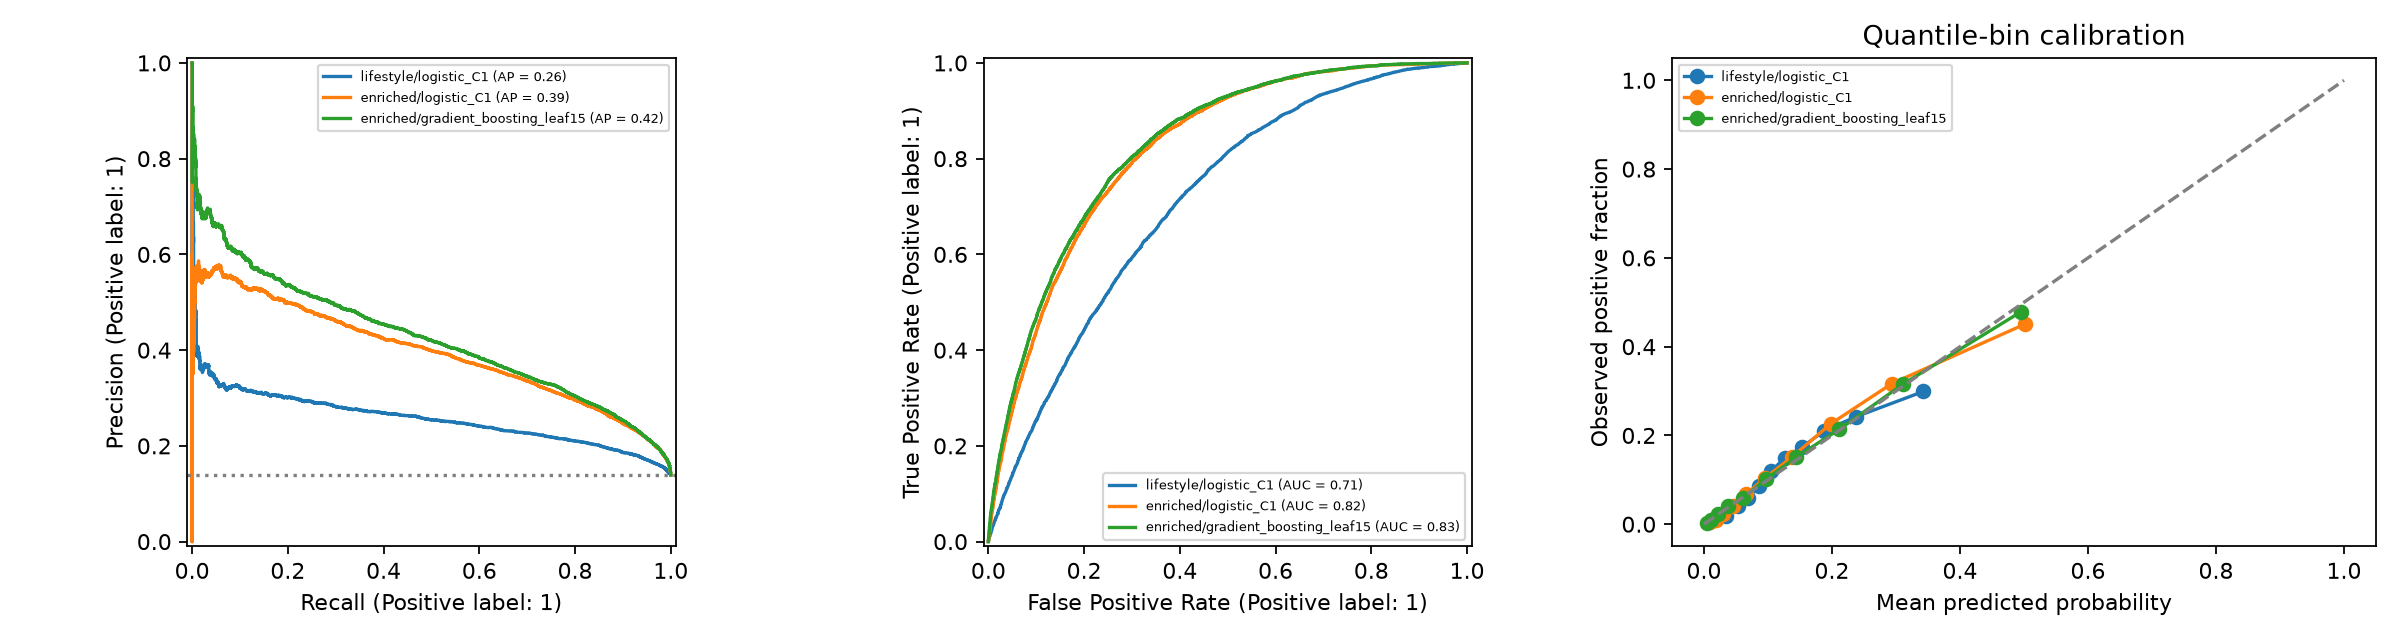

In [6]:
test = pd.read_csv(OUT / "test_metrics.csv")
display(test[test.operating_point == "development_f1"].round(4))
primary = test[(test.candidate == frozen["primary_candidate"]) & (test.operating_point == "development_f1")].iloc[0]
display(pd.DataFrame([[int(primary.tn), int(primary.fp)], [int(primary.fn), int(primary.tp)]],
    index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]))
display(Image(filename=str(OUT / "test_curves.png")))

## 7. Uncertainty and calibration

The primary model has 200 stratified test bootstraps with a fixed model and threshold. The 2.5th and 97.5th percentiles condition on the observed prevalence and do not include uncertainty from training, model selection or survey sampling design. A larger replication budget would give more stable interval endpoints.

Brier loss measures overall probability error; it is not a pure calibration statistic. Quantile-bin reliability curves also depend on binning. No post-hoc calibrator is fitted to the test labels.

In [7]:
uncertainty = json.loads((OUT / "test_intervals.json").read_text())
display(pd.DataFrame(uncertainty["intervals"], index=["lower 2.5%", "upper 97.5%"]).T.round(4))

,lower 2.5%,upper 97.5%
average_precision,0.4141,0.4350
roc_auc,0.8223,0.8317
brier,0.0965,0.0983
precision,0.3724,0.3856
recall,0.6002,0.6203
f1,0.4608,0.4749
accuracy,0.8032,0.8102


## 8. Feature reduction and associations

Selected features are learned anew in every fold, then refitted on all development data. The final subset can differ from individual fold subsets. Compare MI/RFE/L1 logistic models against the full logistic baseline rather than attributing differences from gradient boosting solely to feature count.

Logistic coefficients and odds ratios below are conditional associations per standard-deviation increase. Raw-unit coefficients are also exported. For binary inputs, a full 0-to-1 change is not one standard deviation. No coefficient establishes a causal protective or harmful effect.

In [8]:
display(pd.read_csv(OUT / "selected_features.csv"))
display(pd.read_csv(OUT / "logistic_coefficients.csv").sort_values("coefficient_per_sd", ascending=False).round(4))

,candidate,feature_count,features
0,enriched/gradient_boosting_leaf15,21,"PhysActivity,Fruits,Veggies,Smoker,HvyAlcoholConsump,Sex,Age,Education,Income,BMI,HighBP,HighChol,CholChec..."
1,enriched/l1_C0.01,20,"PhysActivity,Fruits,Veggies,HvyAlcoholConsump,Sex,Age,Education,Income,BMI,HighBP,HighChol,CholCheck,Strok..."
2,enriched/logistic_C1,21,"PhysActivity,Fruits,Veggies,Smoker,HvyAlcoholConsump,Sex,Age,Education,Income,BMI,HighBP,HighChol,CholChec..."
3,enriched/majority,21,"PhysActivity,Fruits,Veggies,Smoker,HvyAlcoholConsump,Sex,Age,Education,Income,BMI,HighBP,HighChol,CholChec..."
4,enriched/mi_k10,10,"Age,Education,Income,BMI,HighBP,HighChol,HeartDiseaseorAttack,GenHlth,PhysHlth,DiffWalk"
5,enriched/rfe_k10,10,"HvyAlcoholConsump,Sex,Age,Income,BMI,HighBP,HighChol,CholCheck,HeartDiseaseorAttack,GenHlth"
6,lifestyle/gradient_boosting_leaf15,9,"PhysActivity,Fruits,Veggies,Smoker,HvyAlcoholConsump,Sex,Age,Education,Income"
7,lifestyle/logistic_C1,9,"PhysActivity,Fruits,Veggies,Smoker,HvyAlcoholConsump,Sex,Age,Education,Income"


,feature,coefficient_per_sd,odds_ratio_per_sd,coefficient_raw_unit
15,GenHlth,0.5722,1.7722,0.5356
9,BMI,0.4083,1.5043,0.0619
6,Age,0.3823,1.4657,0.1253
10,HighBP,0.3738,1.4533,0.7553
11,HighChol,0.2863,1.3315,0.5793
12,CholCheck,0.2376,1.2682,1.2492
5,Sex,0.1257,1.1339,0.2531
14,HeartDiseaseorAttack,0.0654,1.0676,0.2239
18,DiffWalk,0.0479,1.0490,0.1280
13,Stroke,0.0285,1.0289,0.1445


## 9. Error variation and repeated profiles

Age groups use bands 1–5 = 18–44, 6–9 = 45–64 and 10–13 = 65+. The same frozen threshold applies to every subgroup. Compare recall with false-positive rate and precision, while keeping group counts and prevalence in mind. These descriptive differences do not isolate discrimination or establish clinical suitability.

Repeated predictor profiles can cross a random row split because the features are low-resolution survey answers. That is documented below; it is not evidence of repeated people. A grouped-profile sensitivity analysis would answer a different generalization question and remains future work.

In [9]:
display(pd.read_csv(OUT / "subgroup_metrics.csv").round(4))
display(json.loads((OUT / "profile_overlap.json").read_text()))

,variable,group,average_precision,roc_auc,brier,accuracy,balanced_accuracy,precision,recall,f1,false_positive_rate,tn,fp,fn,tp,threshold,n
0,Sex,male,0.4285,0.8127,0.1060,0.7878,0.7165,0.3789,0.6141,0.4686,0.1810,15414,3407,1306,2078,0.2316,22205
1,Sex,female,0.4216,0.8384,0.0905,0.8219,0.7310,0.3812,0.6084,0.4687,0.1465,21207,3639,1443,2242,0.2316,28531
2,Age,18-44,0.2891,0.8568,0.0342,0.9509,0.6348,0.3855,0.2898,0.3308,0.0202,10291,212,326,133,0.2316,10962
3,Age,65+,0.4321,0.7578,0.1402,0.7053,0.6868,0.3746,0.6556,0.4768,0.2819,10232,4017,1264,2406,0.2316,17919
4,Age,45-64,0.4323,0.8303,0.0938,0.8181,0.7284,0.3873,0.6058,0.4725,0.1489,16098,2817,1159,1781,0.2316,21855


{'test_profiles_also_in_development': 6836,
 'test_rows': 50736,
 'interpretation': 'Predictor-profile hash overlap is not proof of participant overlap; retained by design.'}

## 10. Measured conclusions and limits

The richer feature set improves held-out AP for both logistic regression and gradient boosting. RFE with 10 variables retains most of the full logistic model's AP, but this is not a formal equivalence test. The strongest development model uses all 21 predictors.

The cohort is observational and self-reported. Some health indicators may reflect an existing diagnosis, limiting early-detection interpretations. The file does not support survey-weighted prevalence inference or external population claims. The linear treatment of ordinal predictors, small hyperparameter budget, single split and descriptive subgroup comparisons are further limits. The synthetic phase examines controlled failure mechanisms; it does not validate the CDC associations.

In [10]:
lifestyle = test[(test.candidate == "lifestyle/gradient_boosting_leaf15") & (test.operating_point == "development_f1")].iloc[0]
display(Markdown(f"**Primary held-out AP:** {primary.average_precision:.4f}; **ROC-AUC:** {primary.roc_auc:.4f}. "
    f"At the development threshold {primary.threshold:.4f}, recall is {primary.recall:.1%} and precision is {primary.precision:.1%}. "
    f"The lifestyle gradient-boosting comparator has AP {lifestyle.average_precision:.4f}."))

**Primary held-out AP:** 0.4247; **ROC-AUC:** 0.8274. At the development threshold 0.2316, recall is 61.1% and precision is 38.0%. The lifestyle gradient-boosting comparator has AP 0.2763.